# Final Project 2, Part 3: Principal Component Analysis
**DO YOU EVEN LOAF? Does Seoul Bulk or Cut?** | CDS 303

This notebook applies PCA to the variables prepared in
[01_data_integration.ipynb](01_data_integration.ipynb). Each row is one 행정동 in 2025 (365 행정동).
It follows the steps from Demo 6 and the Week 11 lecture:

1. Standardize the data (done in notebook 01)
2. Compute eigenvalues and eigenvectors
3. Select the top *r* components
4. Project the data onto the retained components

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Reproducible settings
RANDOM_STATE = 2000
np.random.seed(RANDOM_STATE)

PROCESSED = Path("../data/processed")
FIGURES = Path("../figures")
FIGURES.mkdir(parents=True, exist_ok=True)

KEY = "Administrative_Dong_Code"

# Plot style: one hue for the data, gray for reference lines, light grid
DATA_COLOR = "#2a78d6"
REF_COLOR = "#8a8984"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})

## 1. Input variables and preprocessing

We load the standardized matrix created in notebook 01, plus the unstandardized table for reference.

In [2]:
X_std = pd.read_csv(PROCESSED / "dong_pca_input_standardized.csv").set_index(KEY)
features = pd.read_csv(PROCESSED / "dong_features_2025.csv").set_index(KEY)

PCA_VARS = X_std.columns.tolist()
print("Rows (행정동):", X_std.shape[0])
print("PCA input variables:", X_std.shape[1])

Rows (행정동): 365
PCA input variables: 8


### 1.1 Variables used

In [3]:
variable_info = pd.DataFrame({
    "variable": PCA_VARS,
    "what it measures": [
        "Share of the 행정동's transactions that go to bakeries",
        "Share of the 행정동's transactions that go to gyms",
        "Share of gym transactions between 06:00 and 11:00",
        "Share of gym transactions between 17:00 and 24:00",
        "Share of bakery customers in their 20s and 30s",
        "Share of gym customers who are female",
        "Bakeries as a share of all stores",
        "Licensed gyms per 1,000 stores",
    ],
    "group": ["Activity", "Activity", "Timing", "Timing", "Customers", "Customers", "Supply", "Supply"],
    "transformation": ["square root", "natural log", "none", "none", "none", "none", "square root", "none"],
})
variable_info

,variable,what it measures,group,transformation
0,bakery_txn_share,Share of the 행정동's transactions that go to bak...,Activity,square root
1,gym_txn_share,Share of the 행정동's transactions that go to gyms,Activity,natural log
2,gym_morning_share,Share of gym transactions between 06:00 and 11:00,Timing,none
3,gym_evening_share,Share of gym transactions between 17:00 and 24:00,Timing,none
4,bakery_young_share,Share of bakery customers in their 20s and 30s,Customers,none
5,gym_female_share,Share of gym customers who are female,Customers,none
6,bakery_store_share,Bakeries as a share of all stores,Supply,square root
7,gym_density,"Licensed gyms per 1,000 stores",Supply,none


### 1.2 How missing values and measurement scale were handled

- **Missing values:** 60 of 425 행정동 had no bakery or no gym transactions in 2025, so their shares could not be calculated.
  We dropped them instead of imputing (see notebook 01). The PCA input has no missing values.
- **Skewness:** bakery_txn_share and bakery_store_share were square-root transformed, and gym_txn_share was log transformed.
- **Scale:** all variables were standardized to mean 0 and standard deviation 1, because PCA is not scale invariant.

We check these below.

In [4]:
checks = pd.DataFrame({
    "missing values": X_std.isna().sum(),
    "mean": X_std.mean().round(3),
    "std": X_std.std(ddof=0).round(3),
})
checks

,missing values,mean,std
bakery_txn_share,0,-0.0,1.0
gym_txn_share,0,0.0,1.0
gym_morning_share,0,0.0,1.0
gym_evening_share,0,-0.0,1.0
bakery_young_share,0,0.0,1.0
gym_female_share,0,0.0,1.0
bakery_store_share,0,0.0,1.0
gym_density,0,0.0,1.0


## 2. Component selection

### 2.1 Fit PCA and compute eigenvalues

We fit PCA with all 8 components first, so we can see how much variance each one explains before deciding how many to keep.
For standardized data, each original variable has variance 1, so the total variance is 8 and the **average eigenvalue is 1**.

In [5]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_std)

n_components = len(PCA_VARS)
pc_names = [f"PC{i}" for i in range(1, n_components + 1)]

variance_table = pd.DataFrame({
    "eigenvalue": pca_full.explained_variance_,
    "explained variance ratio": pca_full.explained_variance_ratio_,
    "cumulative ratio": np.cumsum(pca_full.explained_variance_ratio_),
}, index=pc_names)

print("Total variance:", round(pca_full.explained_variance_.sum(), 3))
print("Average eigenvalue:", round(pca_full.explained_variance_.mean(), 3))
variance_table.style.format({"eigenvalue": "{:.3f}",
                             "explained variance ratio": "{:.1%}",
                             "cumulative ratio": "{:.1%}"})

Total variance: 8.022
Average eigenvalue: 1.003


,eigenvalue,explained variance ratio,cumulative ratio
PC1,1.904,23.7%,23.7%
PC2,1.345,16.8%,40.5%
PC3,1.180,14.7%,55.2%
PC4,1.045,13.0%,68.2%
PC5,0.841,10.5%,78.7%
PC6,0.631,7.9%,86.6%
PC7,0.556,6.9%,93.5%
PC8,0.519,6.5%,100.0%


### 2.2 Scree plot

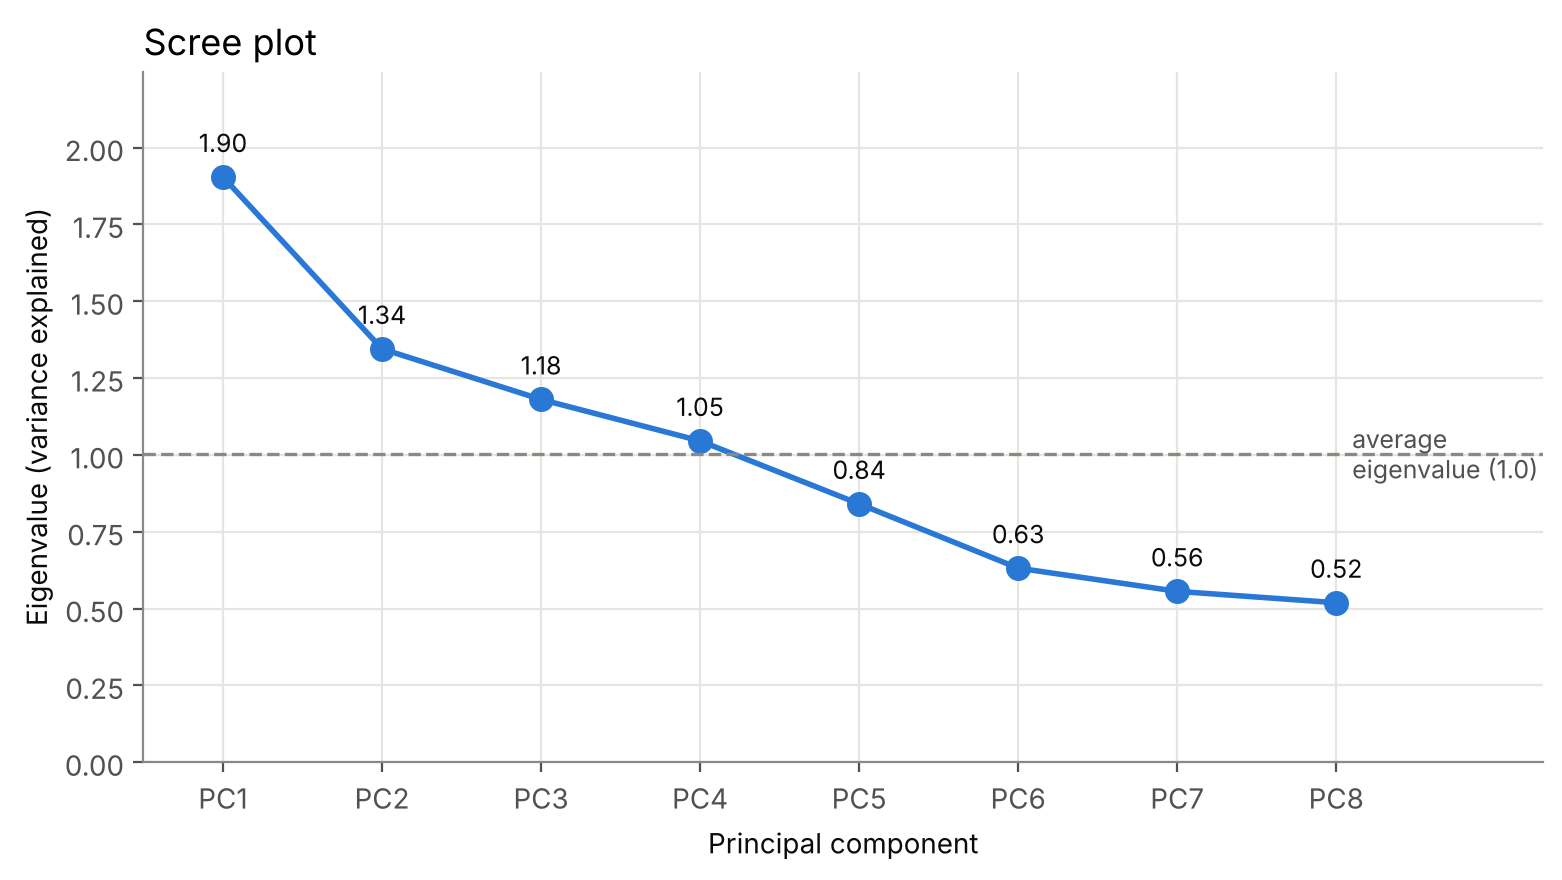

In [6]:
x = np.arange(1, n_components + 1)
avg_eigenvalue = pca_full.explained_variance_.mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, pca_full.explained_variance_, marker="o", markersize=8, linewidth=2, color=DATA_COLOR)
ax.axhline(avg_eigenvalue, linestyle="--", linewidth=1.2, color=REF_COLOR)
ax.text(n_components + 0.1, avg_eigenvalue, "average\neigenvalue (1.0)", va="center", fontsize=9, color="#52514e")
for xi, ev in zip(x, pca_full.explained_variance_):
    ax.annotate(f"{ev:.2f}", (xi, ev), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(x, pc_names)
ax.set_xlim(0.5, n_components + 1.3)
ax.set_ylim(0, pca_full.explained_variance_.max() * 1.18)
ax.set_xlabel("Principal component")
ax.set_ylabel("Eigenvalue (variance explained)")
ax.set_title("Scree plot", loc="left", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES / "p3_scree_plot.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Cumulative explained variance plot

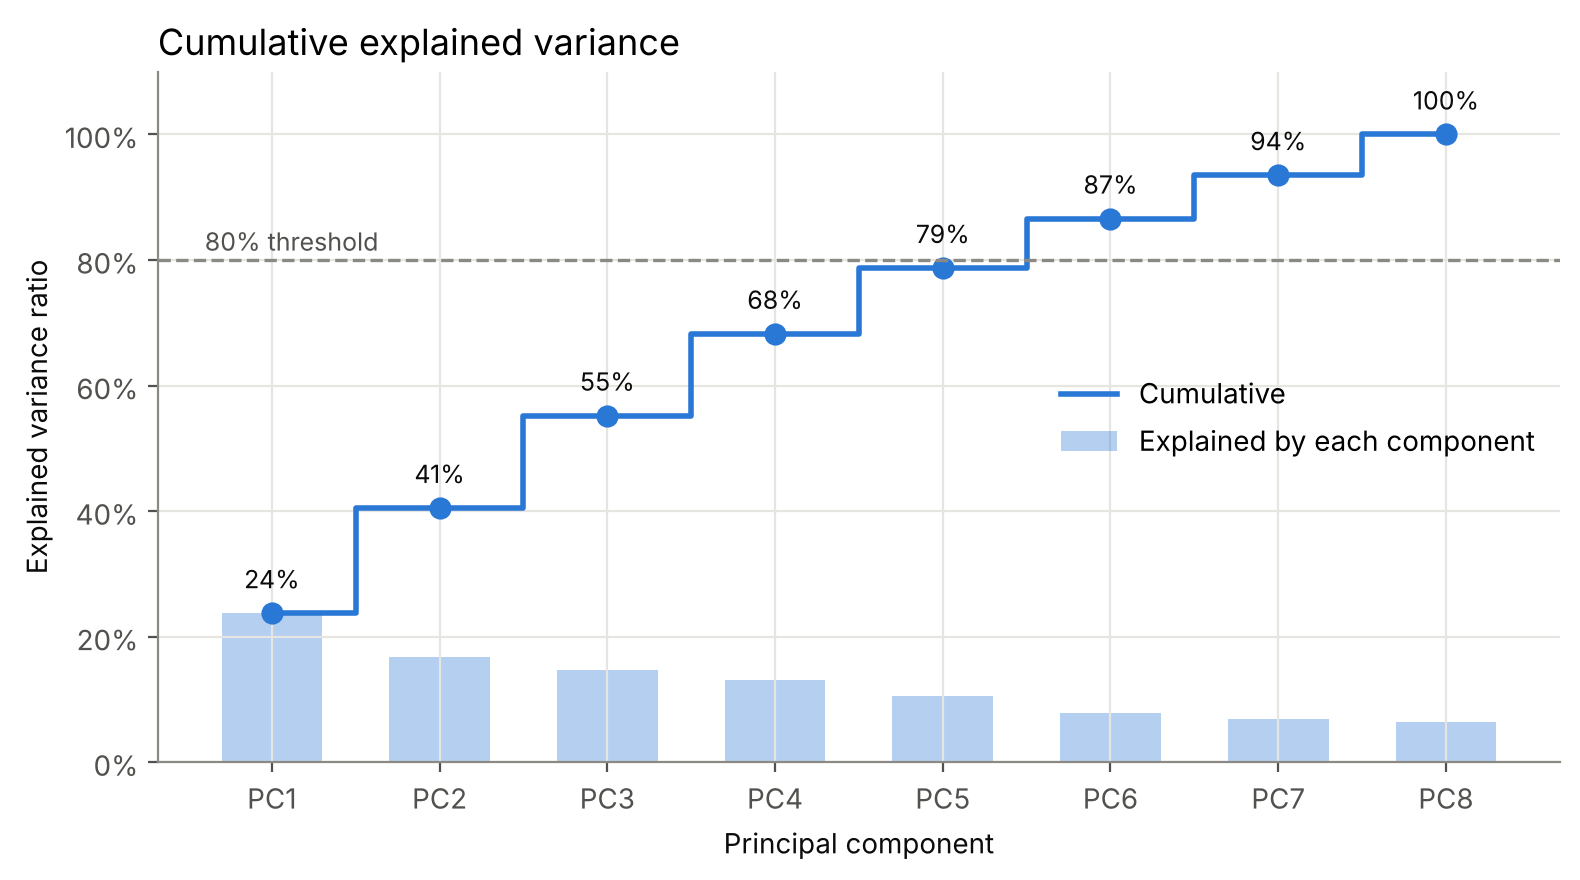

In [7]:
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x, pca_full.explained_variance_ratio_, width=0.6, color=DATA_COLOR, alpha=0.35,
       label="Explained by each component")
ax.step(x, cumulative, where="mid", linewidth=2, color=DATA_COLOR, label="Cumulative")
ax.plot(x, cumulative, "o", markersize=7, color=DATA_COLOR)
ax.axhline(0.8, linestyle="--", linewidth=1.2, color=REF_COLOR)
ax.text(0.6, 0.815, "80% threshold", fontsize=9, color="#52514e")
for xi, c in zip(x, cumulative):
    ax.annotate(f"{c:.0%}", (xi, c), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=9, color="#0b0b0b")
ax.set_xticks(x, pc_names)
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title("Cumulative explained variance", loc="left", fontsize=13)
ax.legend(frameon=False, loc="center right")
plt.tight_layout()
plt.savefig(FIGURES / "p3_cumulative_variance.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4 Selecting the number of components

The Week 11 lecture gives two rules of thumb. We also look at the scree plot.

In [8]:
r_80 = int(np.argmax(cumulative >= 0.8) + 1)
r_above_avg = int((pca_full.explained_variance_ > avg_eigenvalue).sum())

rules = pd.DataFrame({
    "rule": ["Rule 1: cumulative explained variance >= 80%",
             "Rule 2: keep PCs with above-average variance (eigenvalue > 1)"],
    "components": [r_80, r_above_avg],
    "variance kept": [cumulative[r_80 - 1], cumulative[r_above_avg - 1]],
})
rules.style.format({"variance kept": "{:.1%}"})

,rule,components,variance kept
0,Rule 1: cumulative explained variance >= 80%,6,86.6%
1,Rule 2: keep PCs with above-average variance (eigenvalue > 1),4,68.2%


**Decision: we retain 4 components (68.2% of the variance).**

- **Rule 2 (above-average variance) gives 4.** PC1 to PC4 each have an eigenvalue above 1, meaning each one explains more variance
  than a single original variable. PC5 to PC8 each explain less than one original variable (0.84 or lower), so keeping them would not
  summarize the data any better than the variables themselves.
- **Rule 1 (80%) gives 6.** Keeping 6 of 8 components would barely reduce the number of dimensions, which defeats the purpose of PCA
  before clustering (the curse of dimensionality).
- **Scree plot:** the biggest drop is between PC1 and PC2. After that the curve declines gradually and flattens after PC6,
  so there is no single clear elbow. The scree plot does not contradict keeping 4.

**Trade-off:** 4 components keep 68.2% of the variance and lose 31.8%. Our variables are only weakly correlated
(the strongest pair is r = -0.46), so the variance is spread across many directions and no small set of components can reach 80%.
In Project 3 we will also cluster with 6 components to check that the clusters do not change much.

In [9]:
N_RETAIN = r_above_avg
print("Components retained:", N_RETAIN)
print(f"Variance explained: {cumulative[N_RETAIN - 1]:.1%}")

Components retained: 4
Variance explained: 68.2%


### 2.5 Fit the final PCA and save the scores

In [10]:
pca = PCA(n_components=N_RETAIN, random_state=RANDOM_STATE)
scores = pd.DataFrame(pca.fit_transform(X_std), index=X_std.index,
                      columns=[f"PC{i}" for i in range(1, N_RETAIN + 1)])

# Loadings (eigenvectors) for the component interpretation section
loadings = pd.DataFrame(pca.components_.T, index=PCA_VARS, columns=scores.columns)

scores.reset_index().to_csv(PROCESSED / "dong_pca_scores.csv", index=False)
loadings.to_csv(PROCESSED / "pca_loadings.csv")
variance_table.to_csv(PROCESSED / "pca_explained_variance.csv")

print("Saved:", PROCESSED / "dong_pca_scores.csv", scores.shape)
print("Saved:", PROCESSED / "pca_loadings.csv", loadings.shape)
scores.head()

Saved: ../data/processed/dong_pca_scores.csv (365, 4)
Saved: ../data/processed/pca_loadings.csv (8, 4)


,PC1,PC2,PC3,PC4
Administrative_Dong_Code,,,,
11740700,0.676648,1.654410,-0.315373,-1.338464
11740690,1.070205,1.011259,0.953581,2.181605
11740685,-0.113494,-0.027448,-0.808275,0.987039
11740660,0.844171,1.990946,0.623331,-0.961363
11740650,-1.081947,-0.057226,0.542047,-0.110264


## 3. Component interpretation

*(In progress: loading table and heatmap, strongest variables per component, what each component represents.)*

## 4. Visualization and discussion

*(In progress: biplot of PC1 and PC2, visible patterns, link to research question and audience.)*